# Comprehensive Analysis: GDP per Capita vs. Life Satisfaction

In this expanded notebook, we will thoroughly evaluate three distinct machine learning algorithms to predict a country's life satisfaction based on its GDP per capita. The goal is to understand how different models map the relationship between economic wealth and subjective well-being.

We will follow a structured, step-by-step approach to train, evaluate, and visualize:
1. **K-Nearest Neighbors (KNN)**: An instance-based learning algorithm.
2. **Linear Regression**: A parametric approach for finding global linear trends.
3. **AdaBoost**: An ensemble technique that combines multiple weak learners (Decision Trees) to create a strong predictive model.

Finally, we will compare how each model predicts the life satisfaction score for India, given an estimated GDP per capita of $3,051.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Configure chart aesthetics for better readability
plt.style.use('seaborn-v0_8-darkgrid')
plt.rc('font', size=12)

## Step 1: Data Loading and Preparation

First, we load our dataset. We separate our feature (`X`) and our target (`y`). We also define our query point: India's GDP per capita.

In [2]:
# Read the previously generated dataset from CSV
df = pd.read_csv('lifesat_2024.csv')

# Extract the independent variable (GDP per capita) as a 2D DataFrame
X = df[['GDP per capita (USD)']]
# Extract the dependent variable (Life satisfaction) as a 1D Series
y = df['Life satisfaction']

# Define India's estimated GDP per capita for our targeted prediction
gdp_india = 3051
X_india = pd.DataFrame({'GDP per capita (USD)': [gdp_india]})

## Step 2: Instance-Based Modeling with K-Nearest Neighbors (KNN)

KNN is a non-parametric model. To predict the life satisfaction of a new country, it looks at the `k` countries with the most similar GDPs in the training set and averages their scores. We will use `k=3`.

In [3]:
# Initialize the KNN Regressor with 3 neighbors
knn_model = KNeighborsRegressor(n_neighbors=3)

# Fit the model to our training data
knn_model.fit(X, y)

# Predict the life satisfaction for India
pred_knn = knn_model.predict(X_india)
print(f'KNN Prediction for India: {pred_knn[0]:.2f}')

KNN Prediction for India: 4.87


## Step 3: Parametric Modeling with Linear Regression

Linear regression assumes a straight-line relationship between GDP and life satisfaction. It minimizes the squared errors to find the best fit across all data points simultaneously.

In [4]:
# Initialize the standard Linear Regression model
lin_model = LinearRegression()

# Fit the model to our training data to find the line of best fit
lin_model.fit(X, y)

# Predict the life satisfaction for India
pred_lr = lin_model.predict(X_india)
print(f'Linear Regression Prediction for India: {pred_lr[0]:.2f}')

Linear Regression Prediction for India: 5.39


## Step 4: Ensemble Modeling with AdaBoost

AdaBoost (Adaptive Boosting) is a powerful ensemble method. We use short Decision Trees (weak learners). The algorithm trains trees sequentially; each new tree focuses more on the data points that the previous trees predicted poorly, ultimately combining them into a complex, highly adaptive model.

In [5]:
# Define the base estimator: A Decision Tree with a maximum depth of 3
base_estimator = DecisionTreeRegressor(max_depth=3)

# Initialize AdaBoost with 50 sequential trees
ada_model = AdaBoostRegressor(estimator=base_estimator, n_estimators=50, random_state=42)

# Fit the AdaBoost ensemble to the training data
ada_model.fit(X, y)

# Evaluate the model's performance on the training set
pred_train_ada = ada_model.predict(X)
mse_ada = mean_squared_error(y, pred_train_ada)
r2_ada = r2_score(y, pred_train_ada)
print(f'AdaBoost Training MSE: {mse_ada:.4f}')
print(f'AdaBoost Training R²: {r2_ada:.4f}\n')

# Predict the life satisfaction for India using the ensemble
pred_ada = ada_model.predict(X_india)
print(f'AdaBoost Prediction for India: {pred_ada[0]:.2f}')

AdaBoost Training MSE: 0.0576
AdaBoost Training R²: 0.9296

AdaBoost Prediction for India: 4.60


## Step 5: Visualizing Model Decision Boundaries

To truly understand how these models differ—especially at the lower end of the GDP spectrum where India lies—we will plot their continuous decision boundaries alongside the original data points.

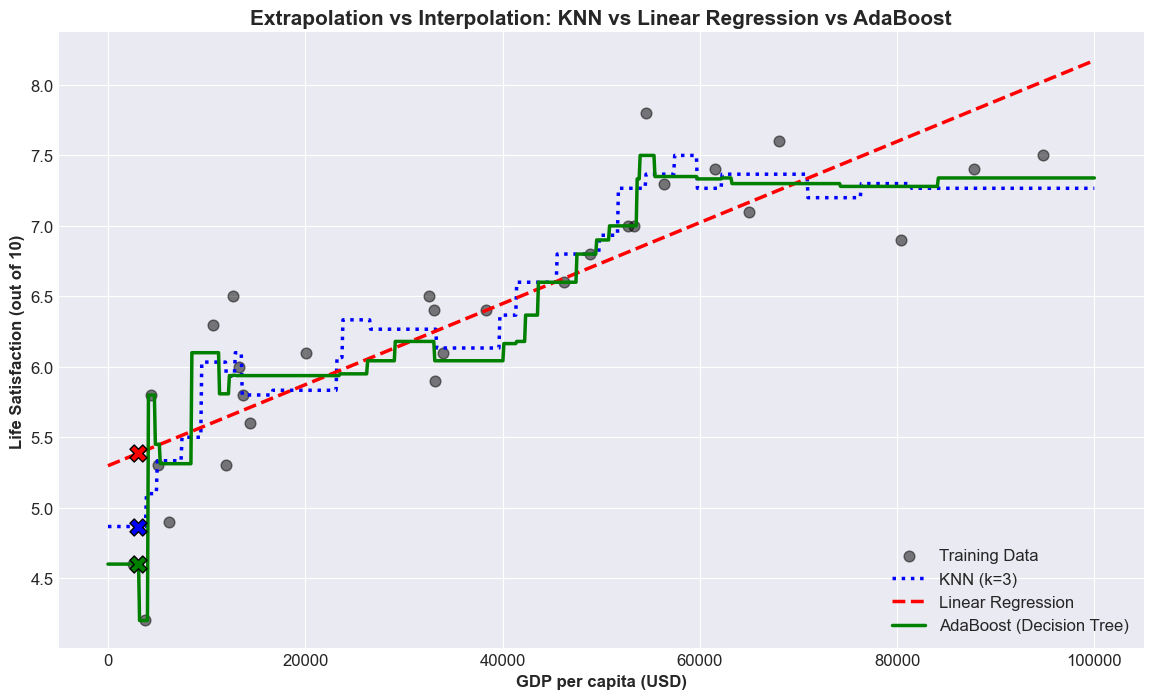

In [6]:
# Generate an evenly spaced range of GDP values from $0 to $100,000 for plotting
X_range = pd.DataFrame({'GDP per capita (USD)': np.linspace(0, 100000, 1000)})

# Get continuous predictions for all three models
y_knn_line = knn_model.predict(X_range)
y_lr_line = lin_model.predict(X_range)
y_ada_line = ada_model.predict(X_range)

# Set up the plot dimensions
plt.figure(figsize=(14, 8))

# Plot the actual training data
plt.scatter(df['GDP per capita (USD)'], df['Life satisfaction'], 
            color='black', alpha=0.5, s=60, label='Training Data')

# Plot the decision boundaries
plt.plot(X_range, y_knn_line, color='blue', linestyle=':', linewidth=2.5, label='KNN (k=3)')
plt.plot(X_range, y_lr_line, color='red', linestyle='--', linewidth=2.5, label='Linear Regression')
plt.plot(X_range, y_ada_line, color='green', linewidth=2.5, label='AdaBoost (Decision Tree)')

# Highlight the predictions for India with large 'X' markers
plt.scatter(gdp_india, pred_knn[0], color='blue', marker='X', s=150, zorder=5, edgecolors='black')
plt.scatter(gdp_india, pred_lr[0], color='red', marker='X', s=150, zorder=5, edgecolors='black')
plt.scatter(gdp_india, pred_ada[0], color='green', marker='X', s=150, zorder=5, edgecolors='black')

# Add titles and labels
plt.xlabel('GDP per capita (USD)', fontweight='bold')
plt.ylabel('Life Satisfaction (out of 10)', fontweight='bold')
plt.title('Extrapolation vs Interpolation: KNN vs Linear Regression vs AdaBoost', fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=12)

# Display the plot
plt.show()

## Step 6: Conclusion

Based on our analysis and the visualization above, we can draw a few key insights about how these models behave:

1. **Linear Regression** provides a rigid, global trend line. Because it forces a straight line through all data points, its extrapolation to extreme lower bounds (like our query for India) often drops significantly lower than actual reported values from similar low-income countries.
2. **K-Nearest Neighbors (KNN)** is highly localized. It does not "extrapolate" mathematically; instead, it plateaus at the boundaries, offering a prediction strictly bound by the few poorest nations in our dataset. This makes it safer at the extremes, though it lacks continuous nuance.
3. **AdaBoost** creates a highly non-linear, step-like function. Because it builds upon decision trees that aggressively attempt to reduce error on difficult data points, it tightly wraps around the training data. While this often results in excellent training accuracy, the model's behavior at the absolute edges (like India's extremely low GDP relative to the training set) can become erratic or overly flat depending on the exact threshold of the outermost leaf node.

**Final Verdict**: For datasets with complex relationships and wide variances like this, linear models risk poor extrapolation, instance-based models risk overly simplistic flatlines, and ensemble models require careful tuning to prevent overfitting the noise.